### 1. Set Seed and Per-Asset Daily Mean and Volatility

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


np.random.seed(42)


n_simulations = 10000
n_days = 252
n_assets = 4


asset_means = np.array([0.0005, 0.0001, 0.0002, 0.0004])
asset_vols = np.array([0.015, 0.005, 0.010, 0.018])


weights = np.array([0.25, 0.25, 0.25, 0.25])

print("Asset Daily Means:", asset_means)
print("Asset Daily Volatilities:", asset_vols)
print("Portfolio Weights:", weights)

Asset Daily Means: [0.0005 0.0001 0.0002 0.0004]
Asset Daily Volatilities: [0.015 0.005 0.01  0.018]
Portfolio Weights: [0.25 0.25 0.25 0.25]


### 2. Simulate 10,000 × 252 × 4 Returns with `np.random.normal`

In [7]:

random_normals = np.random.normal(size=(n_simulations, n_days, n_assets))


daily_returns = random_normals * asset_vols + asset_means

print("Simulated Daily Returns Shape:", daily_returns.shape)

Simulated Daily Returns Shape: (10000, 252, 4)


### 3. Portfolio Paths with Matrix Product, log1p, and exp

In [8]:

portfolio_daily_returns = np.dot(daily_returns, weights)

portfolio_log_returns = np.log1p(portfolio_daily_returns)


cumulative_log_returns = np.sum(portfolio_log_returns, axis=1)


# Assuming starting portfolio value is $1.0
final_portfolio_values = np.exp(cumulative_log_returns)

print("Final Portfolio Values Shape:", final_portfolio_values.shape)

Final Portfolio Values Shape: (10000,)


### 4. Histogram, Volatility, and 95% VaR

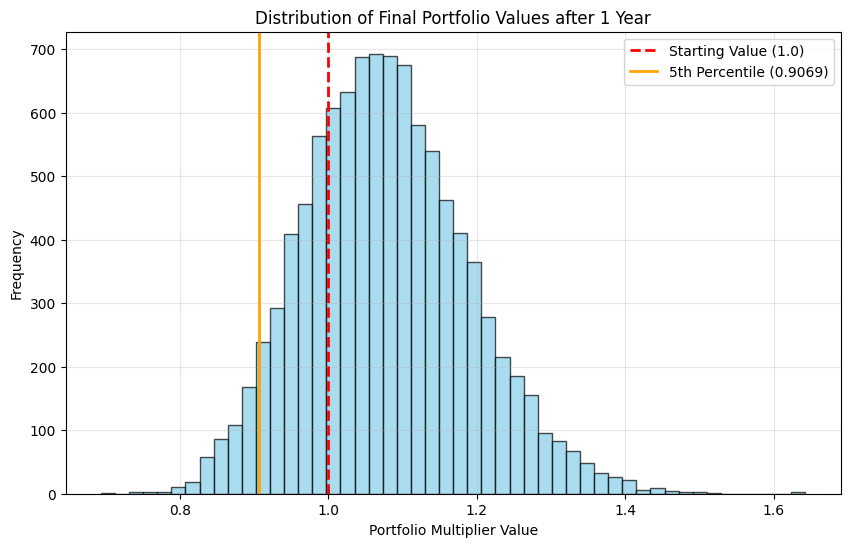

Portfolio Volatility (Std Dev of Outcomes): 11.0673%
95% 1-Year Value-at-Risk (VaR): 9.3100% (Max expected loss with 95% confidence is 9.31% of capital)


In [9]:

portfolio_vol = np.std(final_portfolio_values)


percentile_5 = np.percentile(final_portfolio_values, 5)


var_95 = 1.0 - percentile_5

# Plot the distribution of final portfolio outcomes
plt.figure(figsize=(10, 6))
plt.hist(final_portfolio_values, bins=50, edgecolor='black', alpha=0.7, color='skyblue')
plt.axvline(1.0, color='red', linestyle='--', linewidth=2, label='Starting Value (1.0)')
plt.axvline(percentile_5, color='orange', linestyle='-', linewidth=2, label=f'5th Percentile ({percentile_5:.4f})')

plt.title('Distribution of Final Portfolio Values after 1 Year')
plt.xlabel('Portfolio Multiplier Value')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Portfolio Volatility (Std Dev of Outcomes): {portfolio_vol:.4%}")
print(f"95% 1-Year Value-at-Risk (VaR): {var_95:.4%} (Max expected loss with 95% confidence is {var_95*100:.2f}% of capital)")